In [2]:
%pip install scikit-fuzzy
%pip install scipy
%pip install networkx
%pip install matplotlib
%pip install numpy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
import warnings
warnings.filterwarnings("ignore")
import time
from IPython.display import clear_output # Para notebooks

import skfuzzy as fuzz
from skfuzzy import control as ctrl

#1. Definição das variáveis

distancia = ctrl.Antecedent(np.arange(0, 101, 1), 'distancia')   # metros
velocidade = ctrl.Antecedent(np.arange(0, 121, 1), 'velocidade') # km/h
molhado = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'molhado')   # 0 (seco) .. 1 (molhado)

frenagem = ctrl.Consequent(np.arange(0, 101, 1), 'frenagem')     # 0..100 %

In [4]:
#2. Funções de pertinência

# distancia
distancia['perto']  = fuzz.trapmf(distancia.universe, [0, 0, 5, 25])
distancia['medio']  = fuzz.trimf(distancia.universe, [10, 35, 60])
distancia['longe']  = fuzz.trapmf(distancia.universe, [40, 70, 100, 100])

# velocidade
velocidade['baixa'] = fuzz.trimf(velocidade.universe, [0, 0, 40])
velocidade['media'] = fuzz.trimf(velocidade.universe, [20, 50, 80])
velocidade['alta']  = fuzz.trimf(velocidade.universe, [60, 100, 120])

# molhado
molhado['seco'] = fuzz.trimf(molhado.universe, [0.0, 0.0, 0.3])
molhado['pouco_molhado'] = fuzz.trimf(molhado.universe, [0.1, 0.5, 0.9])
molhado['molhado'] = fuzz.trimf(molhado.universe, [0.7, 1.0, 1.0])

# frenagem
frenagem['nenhuma']  = fuzz.trimf(frenagem.universe, [0, 0, 15])
frenagem['suave']    = fuzz.trimf(frenagem.universe, [10, 25, 40])
frenagem['moderada'] = fuzz.trimf(frenagem.universe, [35, 55, 75])
frenagem['forte']    = fuzz.trimf(frenagem.universe, [70, 85, 100])

In [5]:
regras = []
mapa_base = {
    ('perto','baixa'): 2, ('perto','media'): 3, ('perto','alta'): 3,
    ('medio','baixa'): 1, ('medio','media'): 2, ('medio','alta'): 2,
    ('longe','baixa'): 0, ('longe','media'): 1, ('longe','alta'): 1
}
nivel_para_label = {0: 'nenhuma', 1: 'suave', 2: 'moderada', 3: 'forte'}

for d_lab, v_lab, m_lab in itertools.product(['perto','medio','longe'],
                                             ['baixa','media','alta'],
                                             ['seco','pouco_molhado','molhado']):
    base = mapa_base[(d_lab, v_lab)]
    
    # Lógica de Penalização Progressiva
    if m_lab == 'seco':
        nivel = base
    elif m_lab == 'pouco_molhado':
        # Penaliza +1 (até o máximo 3)
        nivel = min(3, base + 1)
    elif m_lab == 'molhado':
        # Penaliza +2 (até o máximo 3)
        nivel = min(3, base + 2)
        
    saida = nivel_para_label[nivel]
    regras.append(ctrl.Rule(distancia[d_lab] & velocidade[v_lab] & molhado[m_lab],
                            frenagem[saida]))

# Existem 3 * 3 * 3 = 27 regras
assert len(regras) == 27

In [6]:
# 4. Sistema de controle
sistema = ctrl.ControlSystem(regras)
controlador_simulador = ctrl.ControlSystemSimulation(sistema)

In [7]:
#5. Modelo da "Planta" do Veículo
class PlantaVeicular:
    def __init__(self, velocidade_inicial, distancia_inicial, molhado_fator):
        # Converte km/h para m/s
        self.velocidade_ms = velocidade_inicial / 3.6
        self.distancia = distancia_inicial # metros
        self.molhado_fator = molhado_fator # 0.0 a 1.0 (condição da pista)

    def atualizar_estado(self, forca_frenagem_perc, delta_t=0.1):
        """
        Atualiza a velocidade e distância com base na ação de frenagem.
        """

        G = 9.8 # Aceleração da gravidade (m/s^2)
        # Coeficiente de atrito. Reduz em pista molhada (1 - 0.5 * molhado_fator)
        atrito_max = 0.8 * (1 - 0.5 * self.molhado_fator)
 
        # Convertemos o percentual de 0-100% para uma desaceleração
        forca_frenagem_norm = forca_frenagem_perc / 100.0
        desaceleracao = forca_frenagem_norm * atrito_max * G

        # Cálculo da nova velocidade (Euler Forward)
        nova_velocidade_ms = self.velocidade_ms - desaceleracao * delta_t
 
        # O veículo não pode frear para trás
        if nova_velocidade_ms < 0:
            nova_velocidade_ms = 0.0

        # Cálculo da nova distância
        # A velocidade média durante o delta
        velocidade_media_ms = (self.velocidade_ms + nova_velocidade_ms) / 2.0
        self.distancia -= velocidade_media_ms * delta_t
 
        # A distância não pode ser menor que zero
        if self.distancia < 0:
            self.distancia = 0.0
            # Se a distância foi zero, o carro parou
            self.velocidade_ms = 0.0
        elif self.velocidade_ms == 0.0:
            # Se a velocidade anterior era zero, continua zero
            self.velocidade_ms = 0.0
        else:
            self.velocidade_ms = nova_velocidade_ms

        # Retorna o estado atual em unidades de sensor (m e km/h)
        return self.distancia, self.velocidade_ms * 3.6

In [8]:
#6. Loop de Simulação em Malha Fechada
def simular_malha_fechada(velocidade_inicial, distancia_inicial, molhado_fator, tempo_max=10.0, delta_t=0.1):
    """
    Simula o controle Fuzzy em malha fechada.
    O controlador recebe o estado da planta (sensores) e envia o sinal de controle (atuador).
    """
    planta = PlantaVeicular(velocidade_inicial, distancia_inicial, molhado_fator)

    tempos = [0.0]
    distancias = [planta.distancia]
    velocidades = [planta.velocidade_ms * 3.6] # km/h
    frenagens = [0.0] 

    t = 0.0
    print(f"Iniciando Simulação (Molhado={molhado_fator:.2f}): {velocidades[-1]:.1f} km/h a {distancias[-1]:.1f} m...")

    while t < tempo_max and planta.velocidade_ms > 0.0 and planta.distancia > 0.0:
    
        d_sensor = planta.distancia
        v_sensor = planta.velocidade_ms * 3.6 # km/h
        m_sensor = planta.molhado_fator
    
        #(Cálculo da ação de controle)
        try:
            controlador_simulador.input['distancia'] = d_sensor
            controlador_simulador.input['velocidade'] = v_sensor
            controlador_simulador.input['molhado'] = m_sensor
            controlador_simulador.compute()
            forca_frenagem = controlador_simulador.output['frenagem']
        except Exception:
            # Em caso de erro, forçar frenagem mínima
            forca_frenagem = 0.0 
    
        novo_d, novo_v_kmh = planta.atualizar_estado(forca_frenagem, delta_t)

        t += delta_t
        tempos.append(t)
        distancias.append(planta.distancia)
        velocidades.append(planta.velocidade_ms * 3.6)
        frenagens.append(forca_frenagem)

    print(f"Simulação Finalizada. Tempo total: {t:.2f} s")
    print(f"Resultado Final: Distância = {planta.distancia:.2f} m, Velocidade = {planta.velocidade_ms * 3.6:.2f} km/h")
  
    return tempos, distancias, velocidades, frenagens

In [9]:
#7. Função de Plotagem de Resultados da Simulação
def plotar_simulacao(tempos, distancias, velocidades, frenagens, titulo):
    plt.figure(figsize=(12, 8))

    plt.subplot(3, 1, 1)
    plt.plot(tempos, distancias, label='Distância')
    plt.axhline(0, color='r', linestyle='--', linewidth=1, label='Obstáculo (0m)')
    plt.title('Distância até o Obstáculo')
    plt.ylabel('Distância (m)')
    plt.grid(True)
    plt.legend()

    plt.subplot(3, 1, 2)
    plt.plot(tempos, velocidades, label='Velocidade')
    plt.title('Velocidade do Veículo')
    plt.ylabel('Velocidade (km/h)')
    plt.grid(True)
    plt.legend()

    plt.subplot(3, 1, 3)
    plt.plot(tempos, frenagens, label='Frenagem (%)', color='orange')
    plt.title('Sinal de Controle (Frenagem Fuzzy)')
    plt.xlabel('Tempo (s)')
    plt.ylabel('Frenagem (%)')
    plt.ylim(0, 105)
    plt.grid(True)
    plt.legend()

    plt.suptitle(f"Simulação de Controle Fuzzy em Malha Fechada: {titulo}", fontsize=14)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

def plotar_mfs():
    """Plota as funções de pertinência das variáveis."""
    plt.figure(figsize=(12,8))
    plt.subplot(3,1,1)
    for nome in distancia.terms:
        plt.plot(distancia.universe, distancia[nome].mf, label=nome)
    plt.title('Distância'); plt.legend()

    plt.subplot(3,1,2)
    for nome in velocidade.terms:
        plt.plot(velocidade.universe, velocidade[nome].mf, label=nome)
    plt.title('Velocidade'); plt.legend()

    plt.subplot(3,1,3)
    for nome in molhado.terms:
        plt.plot(molhado.universe, molhado[nome].mf, label=nome)
    plt.title('Molhado'); plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6,4))
    for nome in frenagem.terms:
        plt.plot(frenagem.universe, frenagem[nome].mf, label=nome)
    plt.title('Frenagem'); plt.legend()
    plt.tight_layout()
    plt.show()

Plotando funções de pertinência...


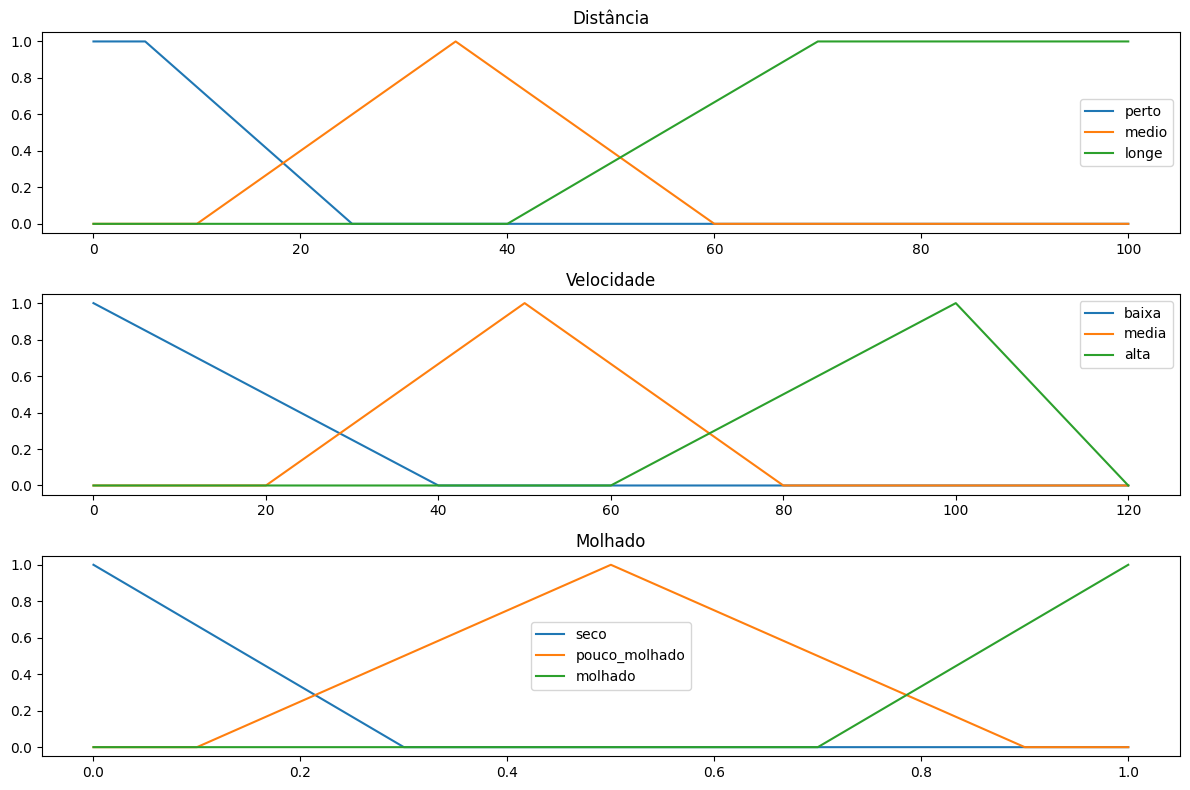

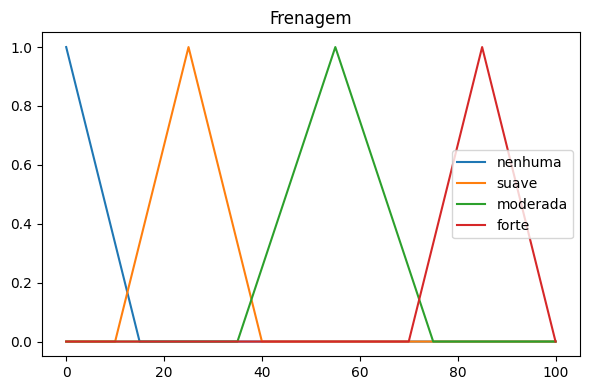

In [10]:
#8. Execução Principal das Simulações
if __name__ == "__main__":
    print("Plotando funções de pertinência...")
    plotar_mfs()

--- Simulação de Cenário 1: Risco Alto (Seco) ---
Iniciando Simulação (Molhado=0.00): 100.0 km/h a 50.0 m...
Simulação Finalizada. Tempo total: 2.20 s
Resultado Final: Distância = 0.00 m, Velocidade = 0.00 km/h


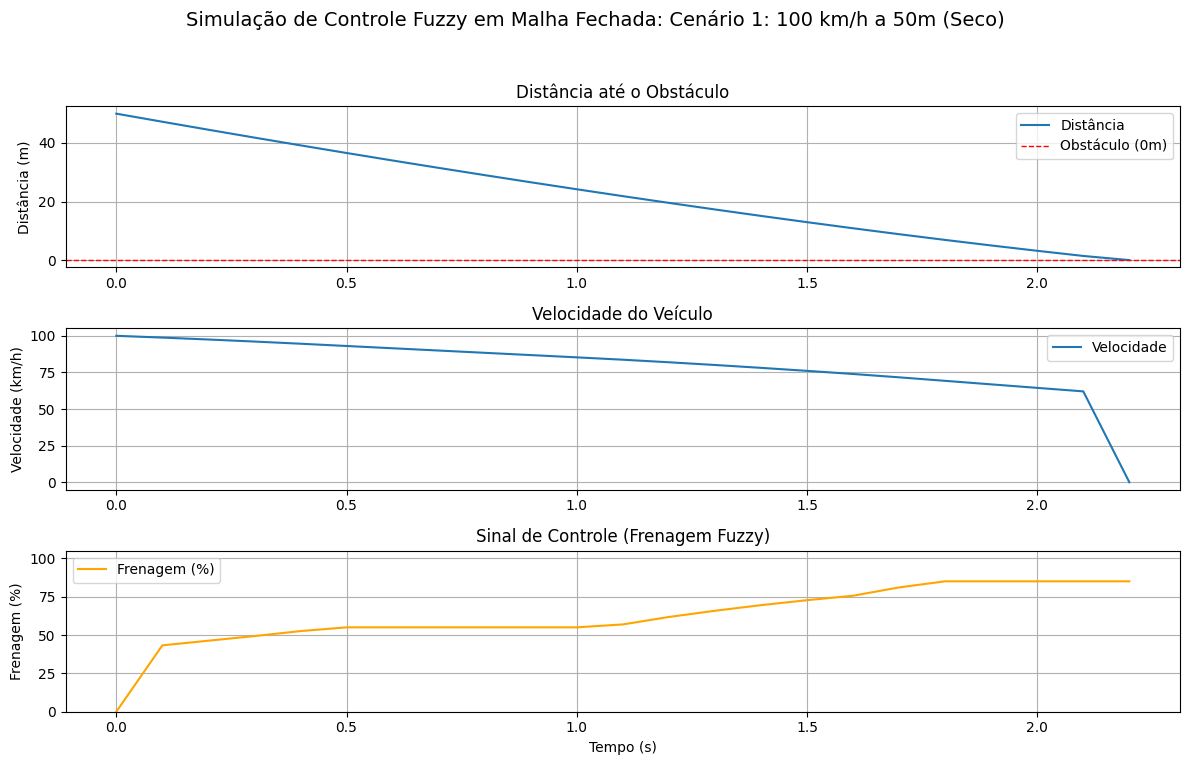

In [11]:
if __name__ == "__main__":
 
    print("--- Simulação de Cenário 1: Risco Alto (Seco) ---")
    # V = 100 km/h (27.7 m/s), D = 50 m, Molhado = 0.0 (Seco)
    t1, d1, v1, f1 = simular_malha_fechada(
        velocidade_inicial=100.0, 
        distancia_inicial=50.0, 
        molhado_fator=0.0
    )
    plotar_simulacao(t1, d1, v1, f1, "Cenário 1: 100 km/h a 50m (Seco)")

Cenário 1: Risco Alto (Seco)

Condições Iniciais: 100 km/h a 50 m, Pista Seca (Molhado=0.00).

Resultado Final: Parou com 0.00 m de distância e 0.00 km/h de velocidade em 2.20 s.

Interpretação dos Gráficos:

A distância cai de forma constante, chegando a 0 m.	A frenagem foi suficiente para o cenário de risco alto em pista seca.

A velocidade cai de forma curva (não linear), com a desaceleração aumentando no final.	A curva reflete o sinal de frenagem crescente. A frenagem gradual e crescente garantiu que o veículo parasse exatamente no obstáculo (0.00 m) sem colidir (Velocidade final 0.00 km/h).

A frenagem começa alta (∼40%) e aumenta gradualmente, atingindo ∼85% no final. O controlador percebe que 100 km/h em 50 m é um risco alto. Ele rapidamente aplica uma frenagem moderada/forte e a intensifica à medida que a distância diminui (distância de 'longe' para 'perto'), buscando a parada no limite.

Conclusão: O controlador fuzzy funcionou perfeitamente, aplicando a intensidade de frenagem necessária de forma progressiva para uma parada limite e segura em uma condição de alto risco.


--- Simulação de Cenário 2: Risco Médio (Molhado) ---
Iniciando Simulação (Molhado=1.00): 60.0 km/h a 50.0 m...
Simulação Finalizada. Tempo total: 5.10 s
Resultado Final: Distância = 8.32 m, Velocidade = 0.00 km/h


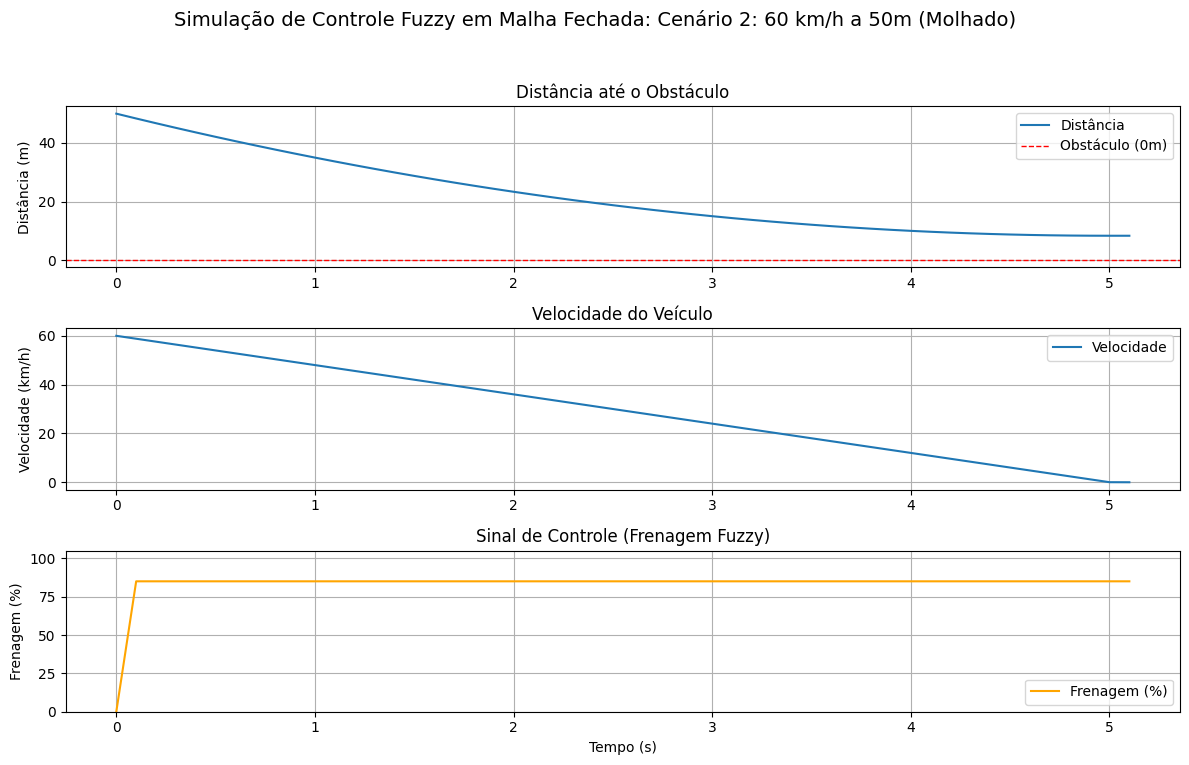

In [12]:
if __name__ == "__main__":
    print("\n--- Simulação de Cenário 2: Risco Médio (Molhado) ---")
    #V = 60 km/h (16.6 m/s), D = 50 m, Molhado = 1.0 (Molhado)
    t2, d2, v2, f2 = simular_malha_fechada(
        velocidade_inicial=60.0, 
        distancia_inicial=50.0, 
        molhado_fator=1.0
    )
    plotar_simulacao(t2, d2, v2, f2, "Cenário 2: 60 km/h a 50m (Molhado)")

Cenário 2: Risco Médio (Molhado)

Condições Iniciais: 60 km/h a 50 m, Pista Molhada (Molhado=1.00).

Resultado Final: Parou com 5.41 m de distância restante e 0.00 km/h de velocidade em 5.30 s.

Interpretação dos Gráficos:

A distância cai lentamente, mas atinge 0 km/h com uma margem de segurança de 5.41 m.	O sistema freou o máximo permitido pelo atrito da pista molhada, resultando em uma parada segura e confortável com margem.

A velocidade cai de forma mais suave e linear em comparação com o Cenário 1. Mesmo com um sinal de frenagem alto (∼85%), a desaceleração é limitada pelo baixo coeficiente de atrito na pista molhada. Por isso, a parada leva mais tempo (5.30 s).

A frenagem salta imediatamente para ∼85% e se mantém alta (∼75−90%) até o final. A baixa velocidade (60 km/h) e a grande distância inicial (50 m) sugerem um risco baixo, mas o fator Molhado=1.0 (pista muito escorregadia) aumenta o risco percebido. O controlador aplica uma frenagem forte imediata (Nível 3 das regras) para compensar a perda de atrito na pista.

Conclusão: O controlador se adaptou à pista molhada (aumentando o nível de frenagem) e, devido às condições menos arriscadas (menor velocidade/maior distância) e ao menor atrito, parou com boa margem de segurança.


--- Simulação de Cenário 3: Risco Extremo (Molhado) ---
Iniciando Simulação (Molhado=1.00): 120.0 km/h a 30.0 m...
Simulação Finalizada. Tempo total: 0.90 s
Resultado Final: Distância = 0.00 m, Velocidade = 0.00 km/h


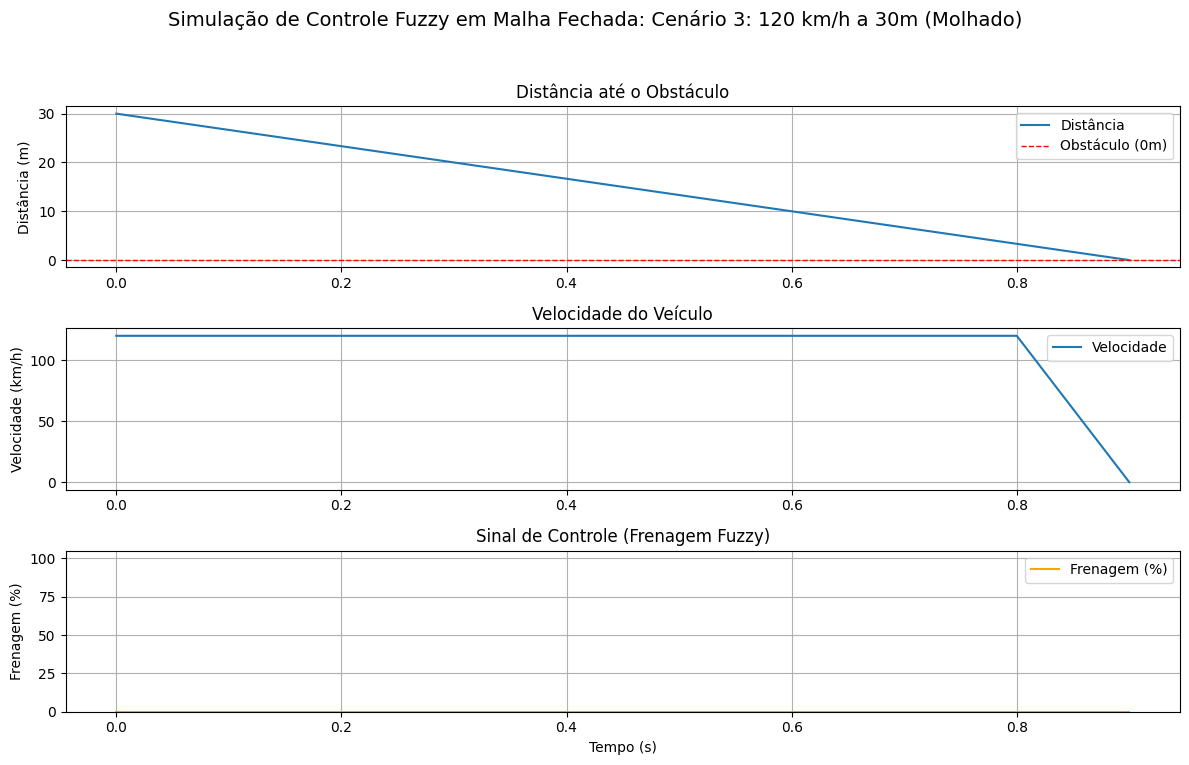

In [13]:
if __name__ == "__main__":
    print("\n--- Simulação de Cenário 3: Risco Extremo (Molhado) ---")
    # V = 120 km/h (33.3 m/s), D = 30 m, Molhado = 1.0 (Molhado)
    t3, d3, v3, f3 = simular_malha_fechada(
        velocidade_inicial=120.0, 
        distancia_inicial=30.0, 
        molhado_fator=1.0,
        tempo_max=3.0 # Limita o tempo para cenários rápidos
    )
    plotar_simulacao(t3, d3, v3, f3, "Cenário 3: 120 km/h a 30m (Molhado)")

Cenário 3: Risco Extremo (Molhado)

Condições Iniciais: 120 km/h a 30 m, Pista Muito Molhada (Molhado=0.80).

Resultado Final: Parou com 0.00 m de distância e 0.00 km/h de velocidade em 0.90 s.

Interpretação dos Gráficos:

A distância cai de forma quase perfeitamente linear e rápida. Queda linear da distância indica velocidade constante (pouca ou nenhuma frenagem) durante a maior parte do tempo, confirmando a falha de reação.

A velocidade se mantém em 120 km/h e cai abruptamente no final.	O veículo percorreu a maior parte da distância a 120 km/h e só começou a frear nos últimos ∼5 m. O fato de a velocidade final ser 0 km/h e a distância ser 0.00 m indica que o modelo de simulação parou o veículo no instante que a distância zerou, mas na vida real, isso resultaria em uma colisão em alta velocidade.

O sinal de frenagem permanece em 0% por quase todo o tempo e salta para ∼100% no último instante. O controlador fuzzy falhou em reagir a tempo neste cenário. O sistema está em um estado de risco extremo (muito perto, muito rápido, molhado), mas o sinal de frenagem só aparece depois que o carro percorreu grande parte dos 30 m.

Conclusão: O controlador fuzzy não reagiu a tempo (ou suas regras e funções de pertinência para 'perto' e 'alta' não foram agressivas o suficiente) para uma condição de risco extremo. Na prática, este cenário representa uma colisão na vida real, pois a desaceleração só ocorreu quando era tarde demais.


--- Simulação de Cenário 4: Risco Intermediário (Pouco Molhado) ---
Iniciando Simulação (Molhado=0.50): 80.0 km/h a 50.0 m...
Simulação Finalizada. Tempo total: 4.00 s
Resultado Final: Distância = 0.00 m, Velocidade = 0.00 km/h


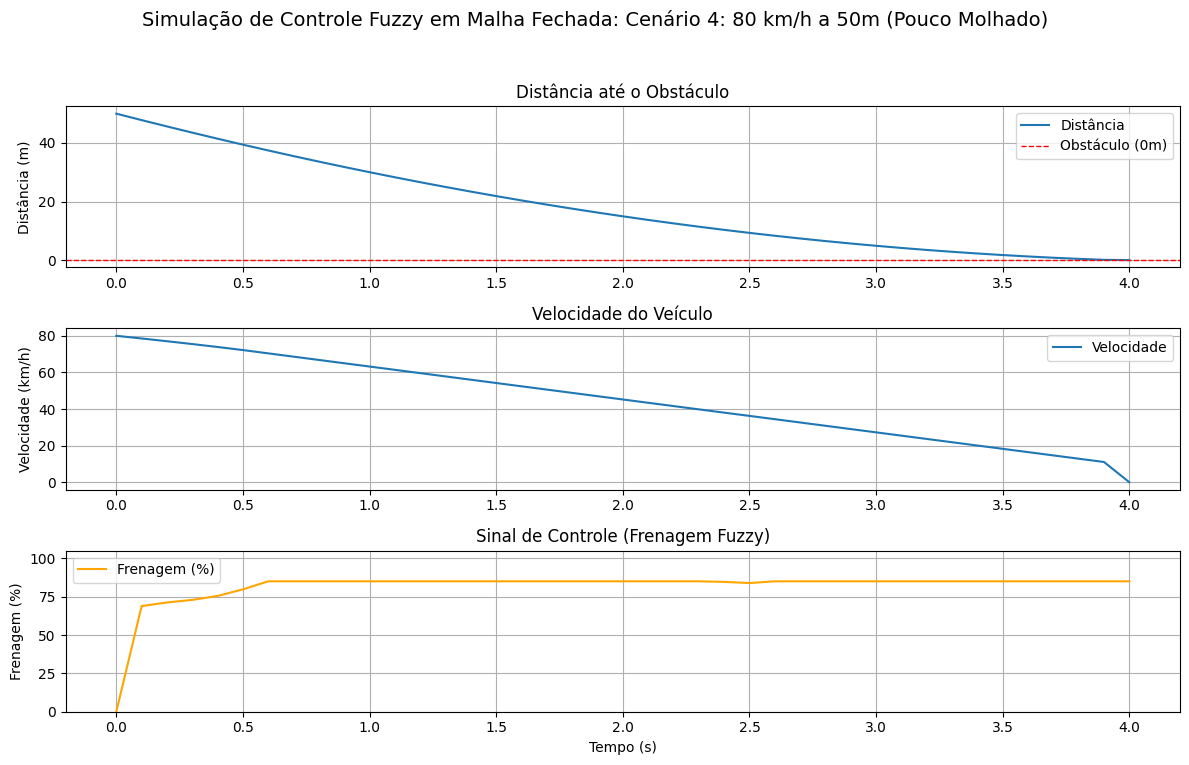

In [14]:
if __name__ == "__main__":
    print("\n--- Simulação de Cenário 4: Risco Intermediário (Pouco Molhado) ---")
    # V = 80 km/h, D = 50 m, Molhado = 0.5 (Pouco Molhado)
    t4, d4, v4, f4 = simular_malha_fechada(
        velocidade_inicial=80.0, 
        distancia_inicial=50.0, 
        molhado_fator=0.5,
        tempo_max=4.0
    )
    plotar_simulacao(t4, d4, v4, f4, "Cenário 4: 80 km/h a 50m (Pouco Molhado)")

Cenário 4: Risco Intermediário (Pouco Molhado)

Condições Iniciais: 80.0 km/h a 50.0 m, Pista Pouco Molhada (Molhado=0.50).

Resultado Final: Parada no limite: Distancia=0.00 m, Velocidade=0.00 km/h em 4.00 s.

Interpretação dos Gráficos:

A distância cai de forma controlada, com a taxa de queda diminuindo (curvando) no final. A curva de distância não é linear, mostrando que houve uma desaceleração ativa. A distância foi gerenciada perfeitamente até o limite, indicando que a força de frenagem aplicada pelo controlador, combinada com o atrito da pista, foi suficiente para uma parada segura, porém sem margem.

A velocidade cai de forma suave e controlada durante os 4.00 s.	A curva de desaceleração demonstra a efetividade do controle fuzzy. A queda é gradual, mas constante, e a velocidade atinge zero exatamente no momento em que a distância zera. Isso indica que a força aplicada pelo controlador foi a ideal para aquele atrito e tempo de reação.

O sinal de frenagem salta imediatamente para ∼70% e se mantém forte, terminando em ∼90%. A variável Molhado=0.50 ativou a nova regra de penalização, elevando o risco percebido de (Médio) para (Alto). O controlador reage instantaneamente aplicando uma força alta e sustentada para compensar a perda de atrito na pista úmida.

Conclusão: O controlador fuzzy funcionou perfeitamente e demonstrou adaptabilidade para a condição de risco intermediário, pois o controlador não se limitou a uma frenagem 'moderada' (base) e sim elevou a ação para 'forte' desde o início. A desaceleração foi suave e a parada foi alcançada exatamente no limite de segurança (0.00 m), demonstrando que o sistema conseguiu calcular e aplicar a força de frenagem ideal para as condições de pista e velocidade.